---

# Tugas Besar 2 IF3170: Prediksi Pembatalan Pemesanan Penginapan

*Eksperimen 02: Decision Tree (CART) from scratch tanpa feature engineering.*

---

## Kelompok 17 DerbyCounty

- NIM - Nama
- NIM - Nama
- NIM - Nama
- NIM - Nama
- 13524093 - Reinsen Silitonga

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Preparation**](#3)
4. [**Modeling dan Validation**](#4)
5. [**Submission**](#5)

---

# Introduction <a name="1"></a>

---

## Aim

*Eksperimen ini mengukur kontribusi feature engineering. Seluruh langkah sama dengan eksperimen 01 (`01_dt_baseline_fe.ipynb`), kecuali tujuh fitur turunan dari `add_features` tidak dibuat. Data Understanding tidak diulang di sini dan dapat dilihat pada notebook eksperimen 01.*

## Approach

| Komponen | Eksperimen 01 | Eksperimen 02 |
| --- | --- | --- |
| Cleaning | buang duplikat, `num_adults = 0` jadi NaN | sama |
| Feature engineering | 7 fitur turunan | **tidak ada** |
| Transformasi | mode `tree`, kategori langka jadi `Other` | sama |
| Model | DT gini, `max_depth=12`, `min_samples_leaf=10` | sama |
| Validasi | stratified 5-fold, seed 42, threshold dari OOF | sama |

---

# Initialization <a name="2"></a>

---

## Import Libraries

In [1]:
import hashlib
import os
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from models import DecisionTree
from preprocessing import TARGET, Preprocessor, clean_train
from utils import (best_threshold, confusion_matrix, cross_val_proba, f1_per_class,
                   fold_scores, load_model, macro_f1, save_model, stratified_kfold)

## Settings

Hyperparameter sengaja disamakan dengan eksperimen 01 agar perbedaan skor hanya berasal dari feature engineering.

In [2]:
class Settings:
    SEED       = 42
    DATA_DIR   = Path('../data')
    OUTPUT_DIR = Path('../output')
    N_FOLDS    = 5

    FEATURE_ENGINEERING = False
    DT_PARAMS  = dict(criterion='gini', max_depth=12, min_samples_leaf=10)

    EXP_NAME   = '02_dt_baseline_no_fe'
    MODEL_PATH = OUTPUT_DIR / 'models' / f'{EXP_NAME}.pkl'
    SUB_PATH   = OUTPUT_DIR / f'submission_{EXP_NAME}.csv'

CFG = Settings()
CFG.OUTPUT_DIR.mkdir(exist_ok=True)

## Seed Everything

In [3]:
def seed_everything(seed: int = 42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(CFG.SEED)

## Load Dataset

In [4]:
train_raw = pd.read_csv(CFG.DATA_DIR / 'train.csv', dtype={'id': str})
test_raw  = pd.read_csv(CFG.DATA_DIR / 'test.csv', dtype={'id': str})
sample    = pd.read_csv(CFG.DATA_DIR / 'sample_submission.csv', dtype={'id': str})

print('train ', train_raw.shape)
print('test  ', test_raw.shape)

train  (27373, 19)
test   (6844, 18)


---

# Data Preparation <a name="3"></a>

---

## 3.1 Data Cleaning dan Transformation

Cleaning sama dengan eksperimen 01. Preprocessor dibuat dengan `feature_engineering=False`, sehingga hanya 17 fitur asli yang dipakai.

In [5]:
train = clean_train(train_raw)
y = train[TARGET].to_numpy()

def make_prep():
    return Preprocessor('tree', feature_engineering=CFG.FEATURE_ENGINEERING)

X_check = make_prep().fit_transform(train)
print('sebelum', train_raw.shape, ' sesudah', train.shape)
print('fitur  ', X_check.shape[1])
print(list(X_check.columns))

sebelum (27373, 19)  sesudah (27309, 19)
fitur   17
['num_adults', 'num_children', 'weekend_nights', 'weekday_nights', 'meal_package', 'needs_parking', 'room_category', 'days_before_arrival', 'arrival_year', 'arrival_month', 'arrival_day', 'booking_channel', 'is_returning_guest', 'prior_cancellations', 'prior_completed_bookings', 'nightly_rate_idr', 'special_requests']


---

# Modeling dan Validation <a name="4"></a>

---

## 4.1 Validasi Silang

Fold yang dipakai identik dengan eksperimen 01 karena seed dan data hasil cleaning sama.

In [6]:
folds = stratified_kfold(y, n_splits=CFG.N_FOLDS, seed=CFG.SEED)

oof = cross_val_proba(lambda: DecisionTree(**CFG.DT_PARAMS), make_prep, train, y, folds)
THRESHOLD, oof_score = best_threshold(y, oof)
per_fold = fold_scores(y, oof, folds, THRESHOLD)

print(f'threshold      {THRESHOLD}')
print(f'Macro F1 OOF   {oof_score:.4f}')
print(f'per fold       {per_fold.round(4)}')
print(f'mean / std     {per_fold.mean():.4f} / {per_fold.std():.4f}')
print('confusion matrix [[TN, FP], [FN, TP]]')
print(confusion_matrix(y, (oof >= THRESHOLD).astype(int)))

threshold      0.43
Macro F1 OOF   0.8271
per fold       [0.8245 0.8302 0.8224 0.8302 0.8279]
mean / std     0.8270 / 0.0031
confusion matrix [[TN, FP], [FN, TP]]
[[16141  2224]
 [ 1967  6977]]


## 4.2 Perbandingan dengan Eksperimen 01

Eksperimen 01 dijalankan ulang di sini dengan fold yang sama agar perbandingan per fold adil.

In [7]:
oof_fe = cross_val_proba(lambda: DecisionTree(**CFG.DT_PARAMS), lambda: Preprocessor('tree'),
                         train, y, folds)
thr_fe, score_fe = best_threshold(y, oof_fe)

comparison = pd.DataFrame({
    '01 dengan FE': fold_scores(y, oof_fe, folds, thr_fe),
    '02 tanpa FE' : per_fold,
}, index=[f'fold {k}' for k in range(CFG.N_FOLDS)])
comparison.loc['OOF'] = [score_fe, oof_score]
comparison['selisih'] = comparison['02 tanpa FE'] - comparison['01 dengan FE']
comparison.round(4)

,01 dengan FE,02 tanpa FE,selisih
fold 0,0.8354,0.8245,-0.0109
fold 1,0.8402,0.8302,-0.0100
fold 2,0.8223,0.8224,0.0002
fold 3,0.8270,0.8302,0.0032
fold 4,0.8205,0.8279,0.0074
OOF,0.8291,0.8271,-0.0021


#### Insights

> Tanpa feature engineering, Macro F1 OOF turun tipis dari 0,8291 menjadi 0,8271. Selisih ini tidak konsisten: eksperimen 01 unggul di fold 0 dan 1, tetapi kalah di fold 3 dan 4, sehingga selisih 0,002 masih berada dalam variasi antar fold. Eksperimen 02 justru lebih stabil (std 0,0031 dibanding 0,0076). Threshold juga bergeser ke 0,43, sehingga model 02 memprediksi lebih banyak pembatalan. Kesimpulannya, ketujuh fitur turunan ini belum memberi peningkatan yang meyakinkan, dan fitur yang lebih kuat perlu dicari.

---

# Submission <a name="5"></a>

---

## 5.1 Training Final, Save, dan Load

Model dilatih ulang dengan seluruh data train lalu disimpan bersama preprocessor dan threshold.

kedalaman 12  jumlah daun 470  threshold 0.43


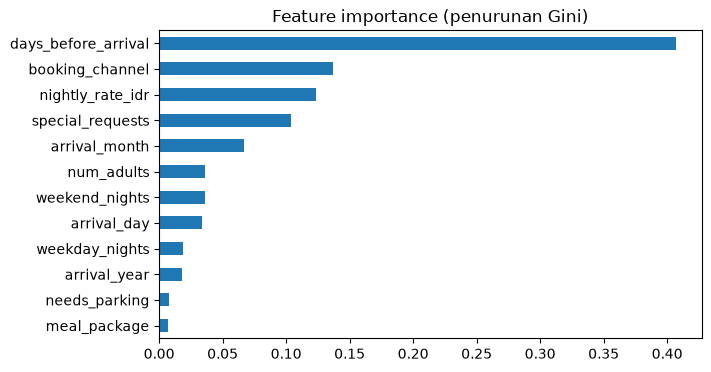

In [8]:
prep_final = make_prep().fit(train)
dt_final = DecisionTree(**CFG.DT_PARAMS).fit(prep_final.transform(train), y)
print('kedalaman', dt_final.get_depth(), ' jumlah daun', dt_final.get_n_leaves(), ' threshold', THRESHOLD)

save_model({'preprocessor': prep_final, 'model': dt_final, 'threshold': THRESHOLD}, CFG.MODEL_PATH)
bundle = load_model(CFG.MODEL_PATH)

importance = pd.Series(dt_final.feature_importances_, index=dt_final.feature_names_)
importance.sort_values().tail(12).plot.barh(figsize=(7, 4), title='Feature importance (penurunan Gini)')
plt.show()

## 5.2 Prediksi dan File Submission

In [9]:
X_test = bundle['preprocessor'].transform(test_raw)
test_pred = bundle['model'].predict(X_test, threshold=bundle['threshold'])

submission = pd.DataFrame({'id': test_raw['id'], 'is_canceled': test_pred})
assert len(submission) == len(sample) and set(submission['id']) == set(sample['id'])
submission.to_csv(CFG.SUB_PATH, index=False)

print(submission['is_canceled'].value_counts(normalize=True).round(4))
print('md5', hashlib.md5(CFG.SUB_PATH.read_bytes()).hexdigest())

is_canceled
0    0.6813
1    0.3187
Name: proportion, dtype: float64
md5 ffc949e5a09061c93f91b25b60c2ab38
